<a href="https://colab.research.google.com/github/aashish003/BIS-LAB_1BF24CS003/blob/main/Parallel_Cellular_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

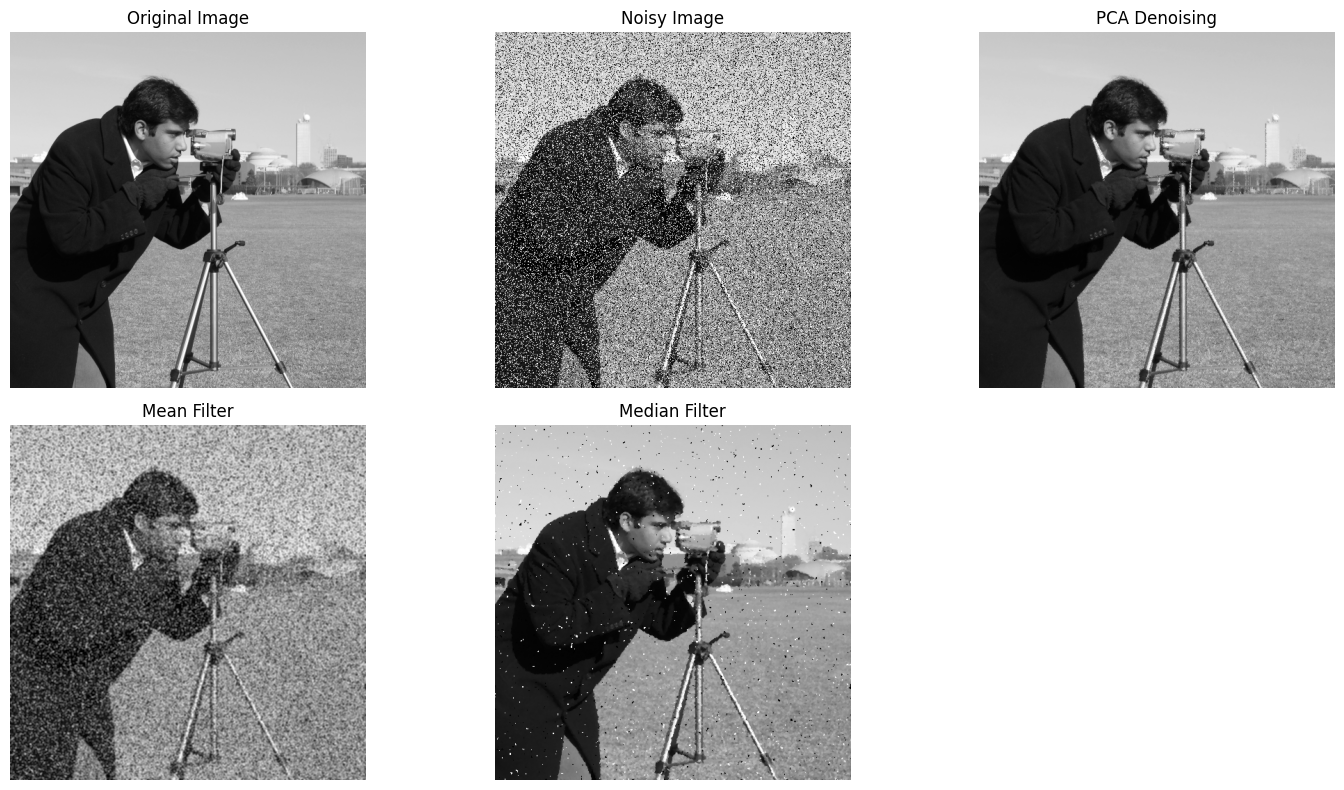


PERFORMANCE COMPARISON

 PCA
PSNR: 32.94
SSIM: 0.9535
MSE: 33.03

 Mean Filter
PSNR: 17.16
SSIM: 0.1874
MSE: 1250.56

 Median Filter
PSNR: 22.63
SSIM: 0.6894
MSE: 354.88


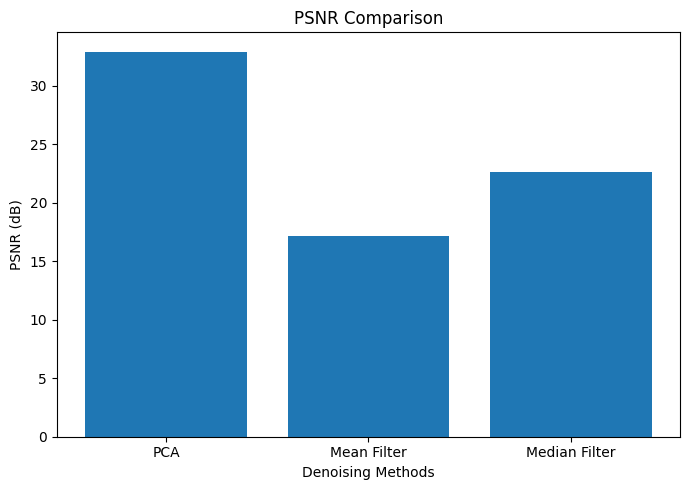

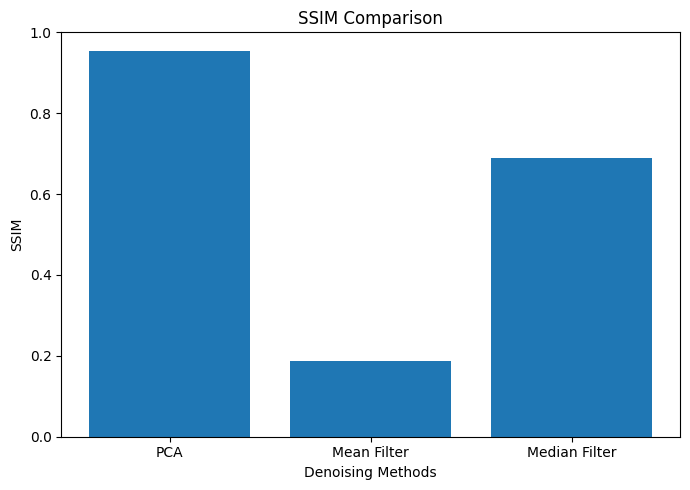

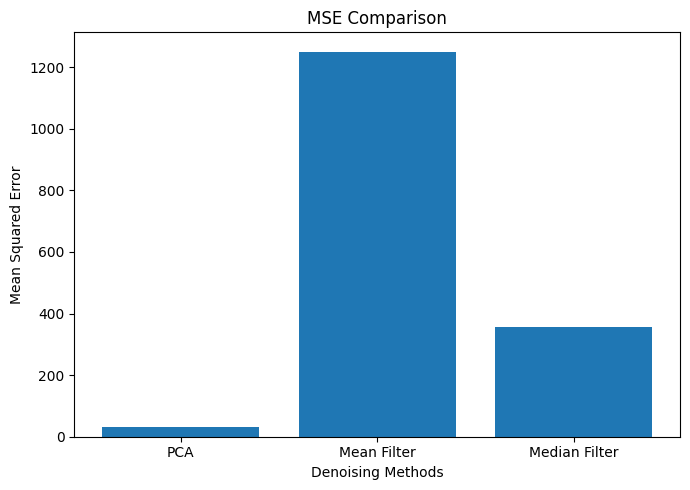

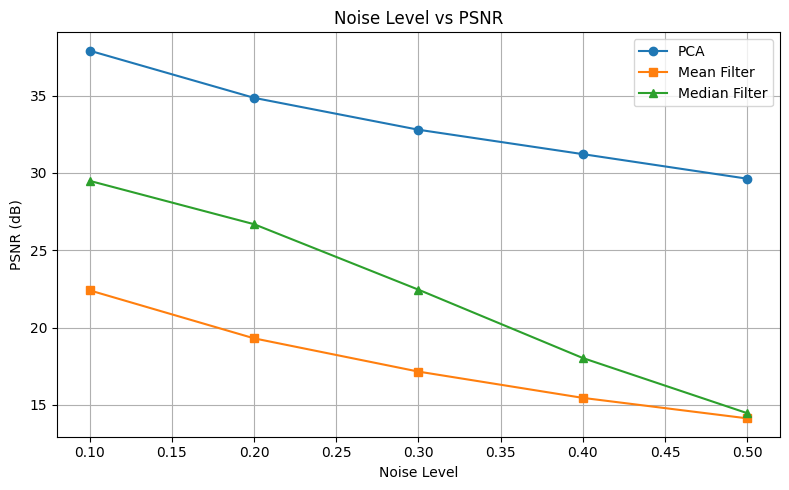

In [2]:

import numpy as np
import matplotlib.pyplot as plt

from skimage import data, util
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity,
    mean_squared_error
)

from scipy.ndimage import uniform_filter, median_filter


# -----------------------------------------
# 1. LOAD ORIGINAL IMAGE
# -----------------------------------------

original = data.camera()
original = original.astype(np.uint8)

# Add salt and pepper noise
np.random.seed(42)

noise_amount = 0.30

noisy = util.random_noise(
    original,
    mode='s&p',
    amount=noise_amount
)

noisy = (noisy * 255).astype(np.uint8)


# -----------------------------------------
# 2. PARALLEL CELLULAR ALGORITHM
# -----------------------------------------

def cellular_automata_denoising(image):

    rows, cols = image.shape

    # Add padding for 5x5 neighborhood
    padded = np.pad(
        image,
        pad_width=2,
        mode='edge'
    )

    # Separate output grid for synchronous updates
    output = image.copy()

    for i in range(rows):
        for j in range(cols):

            # 3x3 neighborhood
            window3 = padded[
                i+1:i+4,
                j+1:j+4
            ]

            center = image[i, j]

            # Extract neighboring pixels
            neighbors3 = window3.flatten()
            neighbors3 = np.delete(neighbors3, 4)

            # Count noisy pixels (0 or 255)
            noisy_count = np.sum(
                (neighbors3 == 0) |
                (neighbors3 == 255)
            )

            # Adaptive neighborhood
            if noisy_count >= 5:

                window = padded[
                    i:i+5,
                    j:j+5
                ]

                neighbors = window.flatten()

                # Remove center pixel
                neighbors = np.delete(neighbors, 12)

            else:

                neighbors = neighbors3

            # Remove salt and pepper pixels
            valid_pixels = neighbors[
                (neighbors != 0) &
                (neighbors != 255)
            ]

            # Update only noisy center pixels
            if center == 0 or center == 255:

                if len(valid_pixels) > 0:
                    output[i, j] = np.mean(valid_pixels)

    return output.astype(np.uint8)


# Apply PCA
pca_result = cellular_automata_denoising(noisy)


# -----------------------------------------
# 3. APPLY MEAN AND MEDIAN FILTERS
# -----------------------------------------

mean_result = uniform_filter(
    noisy.astype(float),
    size=3
).astype(np.uint8)

median_result = median_filter(
    noisy,
    size=3
).astype(np.uint8)


# -----------------------------------------
# 4. DISPLAY IMAGE COMPARISON
# -----------------------------------------

images = [
    original,
    noisy,
    pca_result,
    mean_result,
    median_result
]

titles = [
    "Original Image",
    "Noisy Image",
    "PCA Denoising",
    "Mean Filter",
    "Median Filter"
]

plt.figure(figsize=(15, 8))

for i in range(5):

    plt.subplot(2, 3, i + 1)

    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()


# -----------------------------------------
# 5. CALCULATE PERFORMANCE METRICS
# -----------------------------------------

methods = [
    "PCA",
    "Mean Filter",
    "Median Filter"
]

results = [
    pca_result,
    mean_result,
    median_result
]

psnr_values = []
ssim_values = []
mse_values = []

for result in results:

    psnr = peak_signal_noise_ratio(
        original,
        result,
        data_range=255
    )

    ssim = structural_similarity(
        original,
        result,
        data_range=255
    )

    mse = mean_squared_error(
        original,
        result
    )

    psnr_values.append(psnr)
    ssim_values.append(ssim)
    mse_values.append(mse)


# Print results
print("\nPERFORMANCE COMPARISON")

for i in range(3):

    print("\n", methods[i])
    print("PSNR:", round(psnr_values[i], 2))
    print("SSIM:", round(ssim_values[i], 4))
    print("MSE:", round(mse_values[i], 2))


# -----------------------------------------
# 6. GRAPH 1: PSNR COMPARISON
# -----------------------------------------

plt.figure(figsize=(7, 5))

plt.bar(methods, psnr_values)

plt.title("PSNR Comparison")
plt.xlabel("Denoising Methods")
plt.ylabel("PSNR (dB)")

plt.tight_layout()
plt.show()


# -----------------------------------------
# 7. GRAPH 2: SSIM COMPARISON
# -----------------------------------------

plt.figure(figsize=(7, 5))

plt.bar(methods, ssim_values)

plt.title("SSIM Comparison")
plt.xlabel("Denoising Methods")
plt.ylabel("SSIM")

plt.ylim(0, 1)

plt.tight_layout()
plt.show()


# -----------------------------------------
# 8. GRAPH 3: MSE COMPARISON
# -----------------------------------------

plt.figure(figsize=(7, 5))

plt.bar(methods, mse_values)

plt.title("MSE Comparison")
plt.xlabel("Denoising Methods")
plt.ylabel("Mean Squared Error")

plt.tight_layout()
plt.show()


# -----------------------------------------
# 9. GRAPH 4: NOISE LEVEL VS PSNR
# -----------------------------------------

noise_levels = [0.10, 0.20, 0.30, 0.40, 0.50]

pca_psnr = []
mean_psnr = []
median_psnr = []

for level in noise_levels:

    np.random.seed(42)

    noisy_image = util.random_noise(
        original,
        mode='s&p',
        amount=level
    )

    noisy_image = (
        noisy_image * 255
    ).astype(np.uint8)

    # Apply all three methods
    pca_image = cellular_automata_denoising(
        noisy_image
    )

    mean_image = uniform_filter(
        noisy_image.astype(float),
        size=3
    ).astype(np.uint8)

    median_image = median_filter(
        noisy_image,
        size=3
    ).astype(np.uint8)

    # Calculate PSNR
    pca_psnr.append(
        peak_signal_noise_ratio(
            original,
            pca_image,
            data_range=255
        )
    )

    mean_psnr.append(
        peak_signal_noise_ratio(
            original,
            mean_image,
            data_range=255
        )
    )

    median_psnr.append(
        peak_signal_noise_ratio(
            original,
            median_image,
            data_range=255
        )
    )


# Plot noise level comparison
plt.figure(figsize=(8, 5))

plt.plot(
    noise_levels,
    pca_psnr,
    marker='o',
    label='PCA'
)

plt.plot(
    noise_levels,
    mean_psnr,
    marker='s',
    label='Mean Filter'
)

plt.plot(
    noise_levels,
    median_psnr,
    marker='^',
    label='Median Filter'
)

plt.title("Noise Level vs PSNR")
plt.xlabel("Noise Level")
plt.ylabel("PSNR (dB)")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
